In [1]:
# Purpose: Import libraries and load the engineered soil dataset for model development.
import pandas as pd
import numpy as np

data_path = "../data/processed/sahiwal_soil_dataset_engineered.csv"
soil_data = pd.read_csv(data_path)

print("Dataset shape:", soil_data.shape)
print(soil_data.head())

Dataset shape: (48807, 10)
   longitude  latitude   ph  soc_g_kg  nitrogen_g_kg  clay_pct  sand_pct  \
0  73.166888   30.8821  7.9       7.9           0.92      25.2      43.9   
1  73.169507   30.8821  7.8       8.0           0.92      24.4      43.2   
2  73.172127   30.8821  7.8       8.4           1.02      23.8      43.3   
3  73.174746   30.8821  7.9       9.5           1.11      24.2      41.2   
4  73.177366   30.8821  7.9       9.4           1.10      24.2      40.9   

   silt_pct  cec_cmol_kg soil_texture  
0      30.9         15.6         loam  
1      32.4         15.3         loam  
2      32.9         15.3         loam  
3      34.6         15.4         loam  
4      34.9         14.8         loam  


In [2]:
# Purpose: Separate geographical input features from soil property prediction targets.

location_features = ['longitude', 'latitude']

soil_features = [
    'ph',
    'soc_g_kg',
    'nitrogen_g_kg',
    'clay_pct',
    'sand_pct',
    'silt_pct',
    'cec_cmol_kg'
]

X = soil_data[location_features]
y = soil_data[soil_features]

print("Input features shape:", X.shape)
print("Target features shape:", y.shape)
print("\nInput features:")
print(X.head())

print("\nTarget features:")
print(y.head())

Input features shape: (48807, 2)
Target features shape: (48807, 7)

Input features:
   longitude  latitude
0  73.166888   30.8821
1  73.169507   30.8821
2  73.172127   30.8821
3  73.174746   30.8821
4  73.177366   30.8821

Target features:
    ph  soc_g_kg  nitrogen_g_kg  clay_pct  sand_pct  silt_pct  cec_cmol_kg
0  7.9       7.9           0.92      25.2      43.9      30.9         15.6
1  7.8       8.0           0.92      24.4      43.2      32.4         15.3
2  7.8       8.4           1.02      23.8      43.3      32.9         15.3
3  7.9       9.5           1.11      24.2      41.2      34.6         15.4
4  7.9       9.4           1.10      24.2      40.9      34.9         14.8


In [4]:
# Purpose: Assign each soil sample to a 5 km geographical block.

from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32643",
    always_xy=True
)

x_coords, y_coords = transformer.transform(
    soil_data['longitude'].values,
    soil_data['latitude'].values
)

block_size = 5000  # 5 km in metres

soil_data['block_x'] = np.floor(x_coords / block_size).astype(int)
soil_data['block_y'] = np.floor(y_coords / block_size).astype(int)

soil_data['spatial_block'] = (
    soil_data['block_x'].astype(str) + "_" +
    soil_data['block_y'].astype(str)
)

print("Total spatial blocks:", soil_data['spatial_block'].nunique())
print("\nSamples per block:")
print(soil_data['spatial_block'].value_counts().describe())

Total spatial blocks: 159

Samples per block:
count    159.000000
mean     306.962264
std      131.291679
min        2.000000
25%      227.500000
50%      389.000000
75%      397.000000
max      404.000000
Name: count, dtype: float64


In [7]:
# Purpose: Split geographical blocks into independent training and testing groups.

from sklearn.model_selection import train_test_split

unique_blocks = soil_data['spatial_block'].unique()

train_blocks, test_blocks = train_test_split(
    unique_blocks,
    test_size=0.20,
    random_state=42
)

train_mask = soil_data['spatial_block'].isin(train_blocks)
test_mask = soil_data['spatial_block'].isin(test_blocks)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training blocks:", len(train_blocks))
print("Testing blocks:", len(test_blocks))

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nOverlap between training and testing blocks:",
      len(set(train_blocks) & set(test_blocks)))

Training blocks: 127
Testing blocks: 32

Training samples: 37877
Testing samples: 10930

Overlap between training and testing blocks: 0


In [8]:
# Purpose: Validate training and testing datasets before model training.

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nMissing values:")
print("X_train:", X_train.isnull().sum().sum())
print("y_train:", y_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_test:", y_test.isnull().sum().sum())

Training data:
X_train: (37877, 2)
y_train: (37877, 7)

Testing data:
X_test: (10930, 2)
y_test: (10930, 7)

Missing values:
X_train: 0
y_train: 0
X_test: 0
y_test: 0


In [9]:
# Purpose: Import and configure a baseline multi-output Random Forest regression model.

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestRegressor(n_jobs=-1, random_state=42)


In [10]:
# Purpose: Train the Random Forest model using geographical coordinates and seven soil targets.

import time

start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed successfully!")
print(f"Training time: {training_time:.2f} seconds")

Training completed successfully!
Training time: 2.39 seconds


In [11]:
# Purpose: Generate predictions for all seven soil properties using unseen test locations.

y_pred = rf_model.predict(X_test)

predictions = pd.DataFrame(
    y_pred,
    columns=soil_features,
    index=y_test.index
)

print("Prediction shape:", predictions.shape)
print("\nFirst five predictions:")
print(predictions.head())

Prediction shape: (10930, 7)

First five predictions:
         ph  soc_g_kg  nitrogen_g_kg  clay_pct  sand_pct  silt_pct  \
1740  7.861    10.232         1.0795    22.243    41.051    36.745   
1741  7.861    10.232         1.0795    22.243    41.051    36.745   
1742  7.859    10.236         1.0783    22.262    41.055    36.721   
1743  7.856    10.242         1.0770    22.288    41.067    36.682   
1744  7.858    10.332         1.0811    22.558    41.002    36.476   

      cec_cmol_kg  
1740       14.084  
1741       14.084  
1742       14.096  
1743       14.121  
1744       14.312  


In [12]:
# Purpose: Evaluate geographical soil predictions using regression metrics.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for feature in soil_features:
    mae = mean_absolute_error(y_test[feature], predictions[feature])
    rmse = np.sqrt(mean_squared_error(y_test[feature], predictions[feature]))
    r2 = r2_score(y_test[feature], predictions[feature])

    results.append({
        'Soil Property': feature,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

evaluation_results = pd.DataFrame(results)

print(evaluation_results.round(4))

   Soil Property     MAE    RMSE  R2 Score
0             ph  0.0529  0.0738    0.3882
1       soc_g_kg  0.5665  0.7576    0.1935
2  nitrogen_g_kg  0.0723  0.1271    0.8281
3       clay_pct  0.6986  0.9472    0.5009
4       sand_pct  0.8519  1.1895    0.6592
5       silt_pct  1.0345  1.4969    0.5818
6    cec_cmol_kg  0.6525  0.8695    0.3911


In [13]:
# Purpose: Compare Random Forest performance against a simple mean-value baseline.

from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

baseline_results = []

for i, feature in enumerate(soil_features):
    rf_r2 = r2_score(y_test[feature], predictions[feature])
    dummy_r2 = r2_score(y_test[feature], dummy_pred[:, i])

    baseline_results.append({
        'Soil Property': feature,
        'Random Forest R2': rf_r2,
        'Mean Baseline R2': dummy_r2,
        'Improvement': rf_r2 - dummy_r2
    })

baseline_comparison = pd.DataFrame(baseline_results)

print(baseline_comparison.round(4))

   Soil Property  Random Forest R2  Mean Baseline R2  Improvement
0             ph            0.3882           -0.0006       0.3888
1       soc_g_kg            0.1935           -0.0001       0.1936
2  nitrogen_g_kg            0.8281           -0.0066       0.8347
3       clay_pct            0.5009           -0.0102       0.5110
4       sand_pct            0.6592           -0.0205       0.6797
5       silt_pct            0.5818           -0.0046       0.5863
6    cec_cmol_kg            0.3911           -0.0019       0.3930


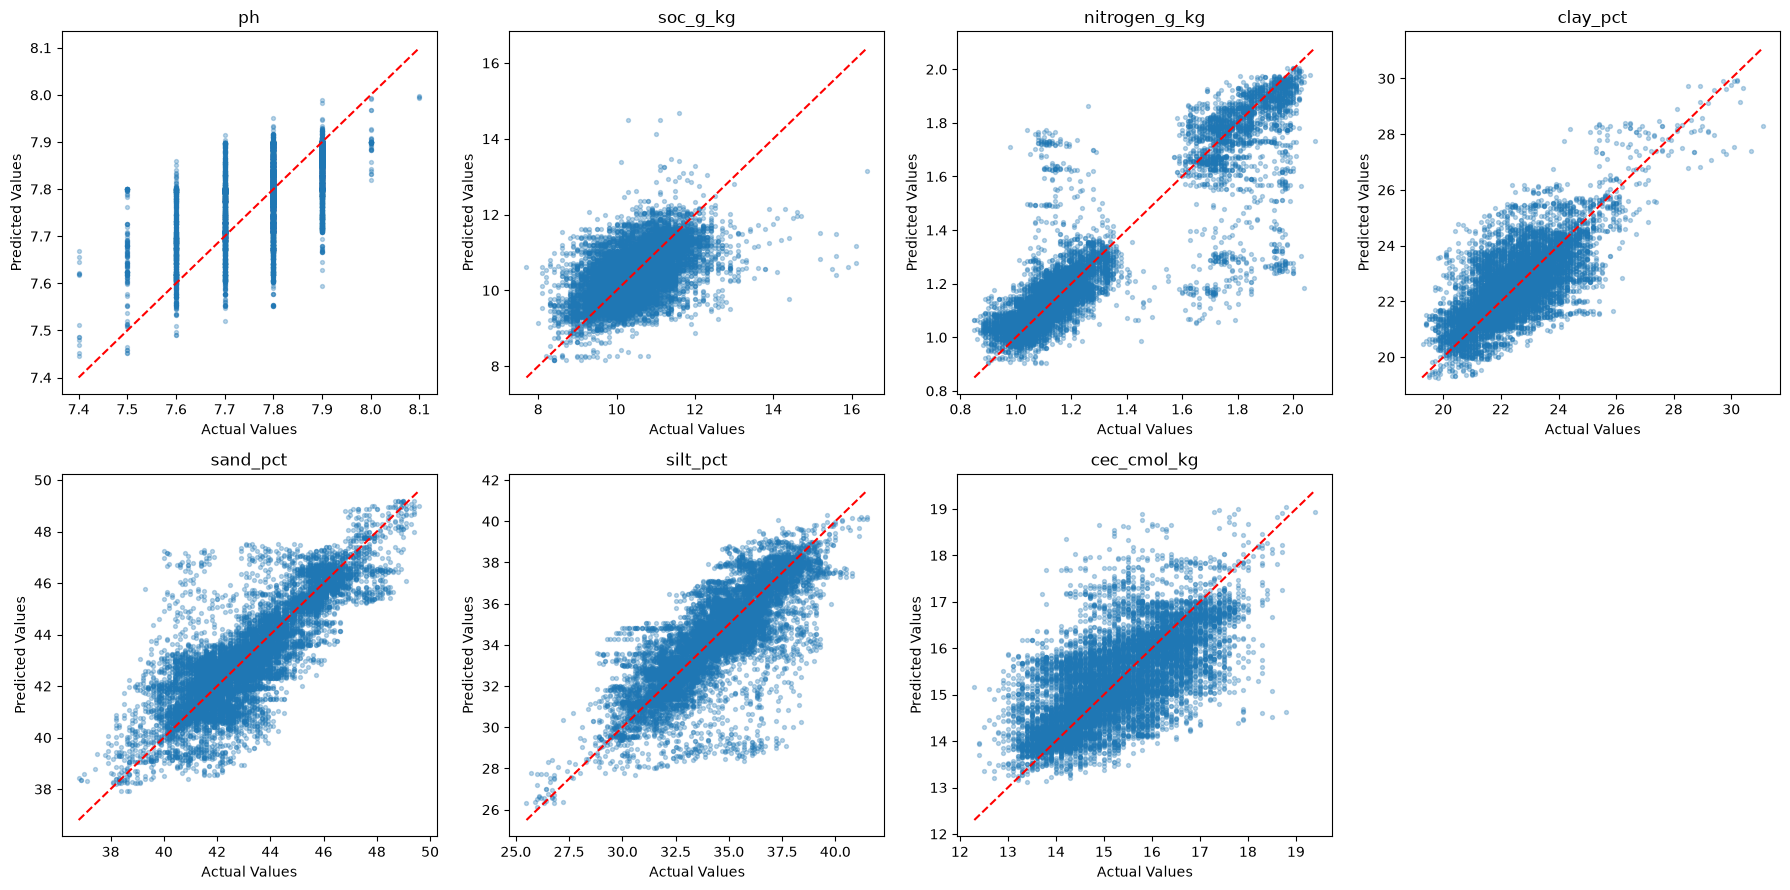

In [14]:
# Purpose: Compare actual and predicted values for all seven soil properties.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, feature in enumerate(soil_features):
    axes[i].scatter(
        y_test[feature],
        predictions[feature],
        alpha=0.3,
        s=8
    )

    minimum = min(y_test[feature].min(), predictions[feature].min())
    maximum = max(y_test[feature].max(), predictions[feature].max())

    axes[i].plot(
        [minimum, maximum],
        [minimum, maximum],
        'r--'
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Actual Values")
    axes[i].set_ylabel("Predicted Values")

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [15]:
# Purpose: Calculate prediction errors and check for systematic overestimation or underestimation.

error_results = []

for feature in soil_features:
    errors = predictions[feature] - y_test[feature]

    error_results.append({
        'Soil Property': feature,
        'Mean Error': errors.mean(),
        'Mean Absolute Error': errors.abs().mean(),
        'Minimum Error': errors.min(),
        'Maximum Error': errors.max()
    })

error_analysis = pd.DataFrame(error_results)

print(error_analysis.round(4))

   Soil Property  Mean Error  Mean Absolute Error  Minimum Error  \
0             ph     -0.0041               0.0529        -0.3050   
1       soc_g_kg     -0.0204               0.5665        -5.3700   
2  nitrogen_g_kg     -0.0029               0.0723        -0.8545   
3       clay_pct      0.0806               0.6986        -4.2340   
4       sand_pct     -0.0025               0.8519        -4.1170   
5       silt_pct     -0.0777               1.0345        -8.6300   
6    cec_cmol_kg      0.0515               0.6525        -4.1710   

   Maximum Error  
0         0.3010  
1         4.1830  
2         0.7324  
3         4.2810  
4         7.2270  
5         4.9820  
6         4.1500  


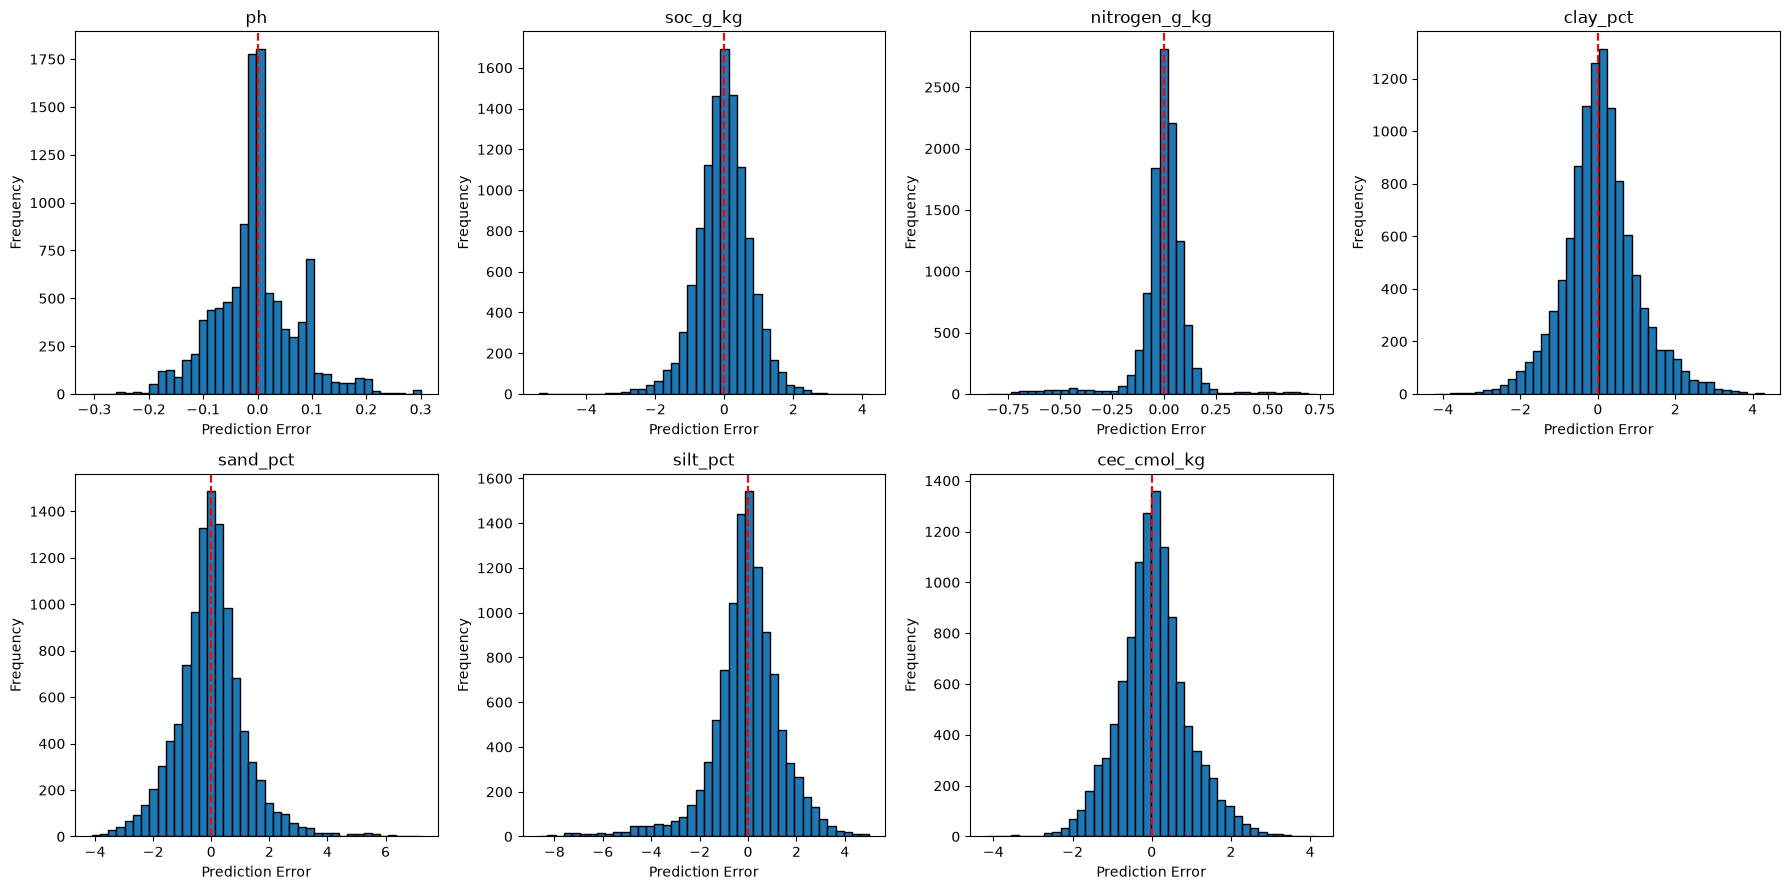

In [16]:
# Purpose: Visualize prediction error distributions for all seven soil properties.

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, feature in enumerate(soil_features):
    errors = predictions[feature] - y_test[feature]

    axes[i].hist(errors, bins=40, edgecolor='black')
    axes[i].axvline(0, color='red', linestyle='--')
    axes[i].set_title(feature)
    axes[i].set_xlabel("Prediction Error")
    axes[i].set_ylabel("Frequency")

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [17]:
# Purpose: Split training data into spatially separate training and validation sets.

from sklearn.model_selection import train_test_split

train_block_ids, validation_block_ids = train_test_split(
    train_blocks,
    test_size=0.20,
    random_state=42
)

new_train_mask = soil_data['spatial_block'].isin(train_block_ids)
validation_mask = soil_data['spatial_block'].isin(validation_block_ids)

X_train_new = X.loc[new_train_mask]
X_validation = X.loc[validation_mask]

y_train_new = y.loc[new_train_mask]
y_validation = y.loc[validation_mask]

print("Training samples:", len(X_train_new))
print("Validation samples:", len(X_validation))
print("Testing samples:", len(X_test))
print("Overlapping blocks:", len(set(train_block_ids) & set(validation_block_ids)))

Training samples: 30851
Validation samples: 7026
Testing samples: 10930
Overlapping blocks: 0


In [18]:
# Purpose: Define candidate Random Forest hyperparameters for optimization.

from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt']
}

print("Number of hyperparameter combinations:",
      3 * 4 * 3 * 3 * 2)

Number of hyperparameter combinations: 216


In [19]:
# Purpose: Search for better Random Forest hyperparameters using spatially separated validation data.

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_error
import time

random_params = list(ParameterSampler(
    param_distributions,
    n_iter=15,
    random_state=42
))

tuning_results = []

for i, params in enumerate(random_params, start=1):

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(X_train_new, y_train_new)

    validation_predictions = model.predict(X_validation)

    mae = mean_absolute_error(
        y_validation,
        validation_predictions
    )

    elapsed = time.time() - start_time

    tuning_results.append({
        'Iteration': i,
        'MAE': mae,
        'Parameters': params,
        'Time (seconds)': elapsed
    })

    print(f"Iteration {i}/15 | MAE: {mae:.5f} | Time: {elapsed:.2f}s")

tuning_results_df = pd.DataFrame(tuning_results)

print("\nBest configuration:")
print(tuning_results_df.loc[tuning_results_df['MAE'].idxmin()])

Iteration 1/15 | MAE: 0.58062 | Time: 1.33s
Iteration 2/15 | MAE: 0.59534 | Time: 0.98s
Iteration 3/15 | MAE: 0.57554 | Time: 1.14s
Iteration 4/15 | MAE: 0.62842 | Time: 1.48s
Iteration 5/15 | MAE: 0.64526 | Time: 1.06s
Iteration 6/15 | MAE: 0.62580 | Time: 1.58s
Iteration 7/15 | MAE: 0.63360 | Time: 9.27s
Iteration 8/15 | MAE: 0.63304 | Time: 4.50s
Iteration 9/15 | MAE: 0.58481 | Time: 1.82s
Iteration 10/15 | MAE: 0.57554 | Time: 2.04s
Iteration 11/15 | MAE: 0.59534 | Time: 0.94s
Iteration 12/15 | MAE: 0.60571 | Time: 0.73s
Iteration 13/15 | MAE: 0.57741 | Time: 3.26s
Iteration 14/15 | MAE: 0.64525 | Time: 1.20s
Iteration 15/15 | MAE: 0.62630 | Time: 2.91s

Best configuration:
Iteration                                                         3
MAE                                                        0.575538
Parameters        {'n_estimators': 100, 'min_samples_split': 5, ...
Time (seconds)                                             1.143467
Name: 2, dtype: object


In [20]:
# Purpose: Extract the best hyperparameter configuration from the tuning results.

best_result = tuning_results_df.loc[tuning_results_df['MAE'].idxmin()]

best_params = best_result['Parameters']

print("Best hyperparameters:")
print(best_params)

print("\nBest validation MAE:", best_result['MAE'])

Best hyperparameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}

Best validation MAE: 0.5755377713211078


In [21]:
# Purpose: Combine training and validation data, then train the optimized Random Forest model.

X_train_final = pd.concat([X_train_new, X_validation])
y_train_final = pd.concat([y_train_new, y_validation])

optimized_model = RandomForestRegressor(
    **best_params,
    random_state=42,
    n_jobs=-1
)

import time

start_time = time.time()

optimized_model.fit(X_train_final, y_train_final)

optimized_training_time = time.time() - start_time

print("Optimized model training completed.")
print("Training samples:", len(X_train_final))
print("Training time:", round(optimized_training_time, 2), "seconds")

Optimized model training completed.
Training samples: 37877
Training time: 1.59 seconds


In [22]:
# Purpose: Evaluate the optimized model on the untouched spatial test dataset.

optimized_predictions_array = optimized_model.predict(X_test)

optimized_predictions = pd.DataFrame(
    optimized_predictions_array,
    columns=soil_features,
    index=y_test.index
)

optimized_results = []

for feature in soil_features:
    mae = mean_absolute_error(
        y_test[feature], optimized_predictions[feature]
    )

    rmse = np.sqrt(mean_squared_error(
        y_test[feature], optimized_predictions[feature]
    ))

    r2 = r2_score(
        y_test[feature], optimized_predictions[feature]
    )

    optimized_results.append({
        'Soil Property': feature,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

optimized_evaluation = pd.DataFrame(optimized_results)

print(optimized_evaluation.round(4))

   Soil Property     MAE    RMSE  R2 Score
0             ph  0.0516  0.0687    0.4697
1       soc_g_kg  0.5234  0.6959    0.3197
2  nitrogen_g_kg  0.0742  0.1234    0.8380
3       clay_pct  0.6427  0.8500    0.5980
4       sand_pct  0.7447  0.9774    0.7699
5       silt_pct  0.9076  1.2075    0.7278
6    cec_cmol_kg  0.6010  0.7835    0.5056


In [23]:
# Purpose: Compare baseline and optimized model performance for every soil property.

comparison = evaluation_results[
    ['Soil Property', 'MAE', 'RMSE', 'R2 Score']
].merge(
    optimized_evaluation,
    on='Soil Property',
    suffixes=('_Baseline', '_Optimized')
)

comparison['MAE Improvement (%)'] = (
    (comparison['MAE_Baseline'] - comparison['MAE_Optimized'])
    / comparison['MAE_Baseline'] * 100
)

comparison['R2 Improvement'] = (
    comparison['R2 Score_Optimized'] - comparison['R2 Score_Baseline']
)

print(comparison.round(4).to_string(index=False))

Soil Property  MAE_Baseline  RMSE_Baseline  R2 Score_Baseline  MAE_Optimized  RMSE_Optimized  R2 Score_Optimized  MAE Improvement (%)  R2 Improvement
           ph        0.0529         0.0738             0.3882         0.0516          0.0687              0.4697               2.4772          0.0815
     soc_g_kg        0.5665         0.7576             0.1935         0.5234          0.6959              0.3197               7.6129          0.1261
nitrogen_g_kg        0.0723         0.1271             0.8281         0.0742          0.1234              0.8380              -2.7021          0.0099
     clay_pct        0.6986         0.9472             0.5009         0.6427          0.8500              0.5980               7.9934          0.0971
     sand_pct        0.8519         1.1895             0.6592         0.7447          0.9774              0.7699              12.5809          0.1107
     silt_pct        1.0345         1.4969             0.5818         0.9076          1.2075        

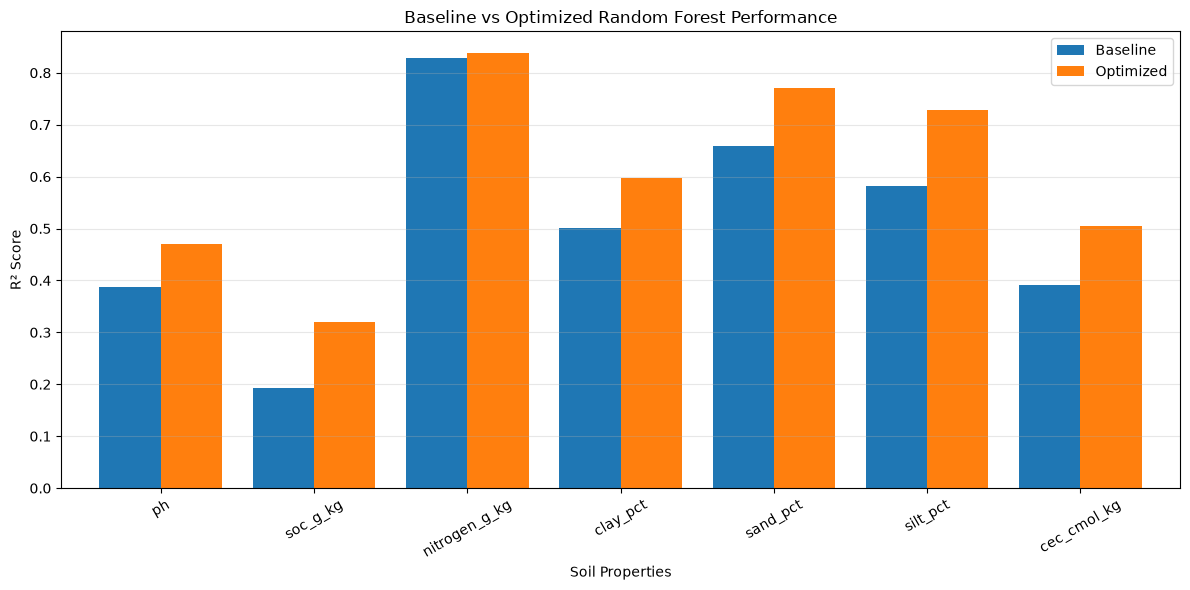

In [24]:
# Purpose: Visualize baseline versus optimized R² scores for all soil properties.

comparison.plot(
    x='Soil Property',
    y=['R2 Score_Baseline', 'R2 Score_Optimized'],
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Baseline vs Optimized Random Forest Performance')
plt.xlabel('Soil Properties')
plt.ylabel('R² Score')
plt.xticks(rotation=30)
plt.legend(['Baseline', 'Optimized'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Purpose: Save the optimized geographical soil prediction model.

import joblib
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/soil_geographical_rf.pkl"

joblib.dump(optimized_model, model_path)

print("Model saved:", model_path)

Model saved: ../models/soil_geographical_rf.pkl


## Module 1: Geographical Soil Prediction

### 1. Objective
Develop a machine learning model that predicts seven soil properties of Sahiwal district using geographical coordinates (longitude and latitude).

### 2. Dataset
- Total samples: 48,807
- Input features: Longitude and latitude
- Target variables: pH, SOC, nitrogen, clay, sand, silt, and CEC.
- Data source: SoilGrids (250m resolution).
- Train/test split: Spatial block-based splitting using 5 km blocks.

### 3. Baseline Model
A Random Forest Regressor with 100 trees was trained using the geographical coordinates.

Baseline performance:

| Soil Property | MAE | RMSE | R² |
|---|---:|---:|---:|
| pH | 0.0529 | 0.0738 | 0.3882 |
| SOC | 0.5665 | 0.7576 | 0.1935 |
| Nitrogen | 0.0723 | 0.1271 | 0.8281 |
| Clay | 0.6986 | 0.9472 | 0.5009 |
| Sand | 0.8519 | 1.1895 | 0.6592 |
| Silt | 1.0345 | 1.4969 | 0.5818 |
| CEC | 0.6525 | 0.8695 | 0.3911 |

### 4. Hyperparameter Optimization
Randomized hyperparameter search tested 15 configurations using a spatially separated validation dataset.

**Selected hyperparameters:**
- Number of estimators: 100
- Maximum depth: 30
- Minimum samples split: 5
- Minimum samples leaf: 1
- Maximum features: sqrt

Best validation MAE: 0.57554.

### 5. Optimized Model Performance

| Soil Property | MAE | RMSE | R² |
|---|---:|---:|---:|
| pH | 0.0516 | 0.0687 | 0.4697 |
| SOC | 0.5234 | 0.6959 | 0.3197 |
| Nitrogen | 0.0742 | 0.1234 | 0.8380 |
| Clay | 0.6427 | 0.8500 | 0.5980 |
| Sand | 0.7447 | 0.9774 | 0.7699 |
| Silt | 0.9076 | 1.2075 | 0.7278 |
| CEC | 0.6010 | 0.7835 | 0.5056 |

### 6. Baseline vs Optimized Results
- MAE improved for six out of seven properties.
- R² improved for all seven properties.
- Average MAE reduction: approximately 6.87%.
- Average absolute R² improvement: approximately 0.0980.
- Sand and silt showed the largest MAE improvements.
- SOC remained the most challenging prediction target.
- Nitrogen maintained the strongest R² score.

### 7. Conclusion
The optimized Random Forest model demonstrated improved geographical soil prediction performance compared with the baseline model. It learned useful spatial patterns from geographical coordinates and achieved its strongest results for nitrogen, sand, and silt.

The trained model was saved for future use:

`models/soil_geographical_rf.pkl`

### 8. Important Limitation
The model predicts SoilGrids-derived estimates rather than independently collected laboratory measurements. Therefore, its performance measures how well it reproduces SoilGrids spatial patterns, not necessarily the accuracy of actual soil conditions.